In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

PRETRAINED_MODELS_RESULTS_CSV = 'results/modelsubject_correlations_nsd515.csv'

TRAINED_MODELS_DICT = {
    'rn18_imgnet_finetuned_faceclassification': "/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_classification/evaluation/f5b95b1f-31fd-47c4-a6fb-2e52f709349a",
    'rn18_scratch_faceclassification': "/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_classification/evaluation/f2c52f72-351f-4a13-9865-209d6edacf56"
}

model_fmri_frois = [
    ('FFA', 'FFA'),
    ('PPA', 'PPA'),
    ('EBA', 'EBA'),
]
model_localizer = 'grillspector'
tthreshold = 7

pretrained_results_csv = pd.read_csv(PRETRAINED_MODELS_RESULTS_CSV)

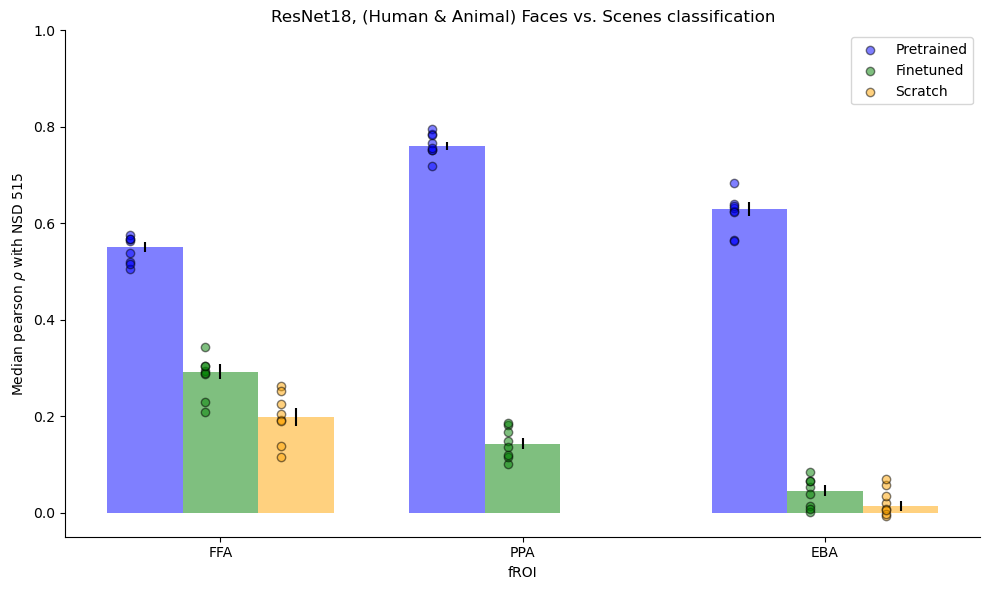

In [43]:
froi_pearsonrs_plot_data = {}
for (model_froi, fmri_froi) in model_fmri_frois:
    # ResNet18 trained on ImageNet
    resnet18_imagenet_pearsonrs = pretrained_results_csv[
        (pretrained_results_csv['model_name'] == 'resnet18imagenet1kv1') &
        (pretrained_results_csv['model_froi'] == model_froi) &
        (pretrained_results_csv['fmri_froi'] == fmri_froi) &
        (pretrained_results_csv['fmri_tthreshold'] == tthreshold) &
        (pretrained_results_csv['model_localizer'] == model_localizer) &
        (pretrained_results_csv['model_tthreshold'] == tthreshold)
    ]['normed_pearsonr'].tolist()

    # ResNet18 trained on ImageNet and fine-tuned on face classification
    resnet18_imgenet_finetuned_fc_csv = pd.read_csv(
        TRAINED_MODELS_DICT['rn18_imgnet_finetuned_faceclassification'] + '/nsd515_correlations.csv'
    )
    resnet18_imgenet_finetuned_fc_pearsonrs = resnet18_imgenet_finetuned_fc_csv[
        (resnet18_imgenet_finetuned_fc_csv['model_froi'] == model_froi) &
        (resnet18_imgenet_finetuned_fc_csv['fmri_froi'] == fmri_froi) &
        (resnet18_imgenet_finetuned_fc_csv['fmri_tthreshold'] == tthreshold) &
        (resnet18_imgenet_finetuned_fc_csv['model_localizer'] == model_localizer) &
        (resnet18_imgenet_finetuned_fc_csv['model_tthreshold'] == tthreshold)
    ]['normed_pearsonr'].tolist()
    resnet18_imgenet_finetuned_fc_pearsonrs = [float(x) for x in resnet18_imgenet_finetuned_fc_pearsonrs]

    # ResNet18 trained from scratch on face classification
    resnet18_scratch_fc_csv = pd.read_csv(
        TRAINED_MODELS_DICT['rn18_scratch_faceclassification'] + '/nsd515_correlations.csv'
    )
    resnet18_scratch_fc_pearsonrs = resnet18_scratch_fc_csv[
        (resnet18_scratch_fc_csv['model_froi'] == model_froi) &
        (resnet18_scratch_fc_csv['fmri_froi'] == fmri_froi) &
        (resnet18_scratch_fc_csv['fmri_tthreshold'] == tthreshold) &
        (resnet18_scratch_fc_csv['model_localizer'] == model_localizer) &
        (resnet18_scratch_fc_csv['model_tthreshold'] == tthreshold)
    ]['normed_pearsonr'].tolist()
    resnet18_scratch_fc_pearsonrs = [float(x) for x in resnet18_scratch_fc_pearsonrs]
    
    # Store data for plotting
    froi_pearsonrs_plot_data[model_froi] = [
        resnet18_imagenet_pearsonrs,
        resnet18_imgenet_finetuned_fc_pearsonrs,
        resnet18_scratch_fc_pearsonrs
    ]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['blue', 'green', 'orange']
labels = ['Pretrained', 'Finetuned', 'Scratch']
for xidx, (model_froi, fmri_froi) in enumerate(froi_pearsonrs_plot_data.items()):
    froi_pearsonrs = froi_pearsonrs_plot_data[model_froi]
    for idx, pearsonrs in enumerate(froi_pearsonrs):
        xpt = xidx + 0.25 * (idx - 1)
        ax.bar(
            xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
            label=model_froi, color=colors[idx], width=0.25
        )
        ax.scatter(
            np.array([xpt]*len(pearsonrs))-0.05, pearsonrs, color=colors[idx], alpha=0.5, ec='k'
        )
ax.set_ylim(-0.05, 1)
ax.set_xticks(np.arange(len(froi_pearsonrs_plot_data)), froi_pearsonrs_plot_data.keys())
ax.set_ylabel(r'Median pearson $\rho$ with NSD 515')
ax.set_xlabel('fROI')
ax.set_title('ResNet18, (Human & Animal) Faces vs. Scenes classification')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(labels)
plt.tight_layout()
plt.show()